# UPI Transactions 2024 — Data Cleaning & Exploratory Data Analysis

**Hackathon:** KLU + Path-3 ML-02 — Real-Time UPI / Digital Payment Fraud Detection  
**Dataset:** `upi_transactions 2024.csv`

## Objectives
1. Load the original transaction dataset and inspect its structure.
2. Audit missing values, duplicate records, duplicate transaction IDs, invalid values and timestamp consistency.
3. Clean and standardize fields without deleting potentially informative fraud transactions.
4. Create useful time-based features.
5. Visualize class imbalance and fraud patterns across transaction attributes.
6. Export a cleaned dataset for the next modelling stage.

> **Important modelling note:** This notebook is for cleaning and EDA, not model training. `transaction_status` may contain information that is unavailable at the moment a payment decision must be made. Treat it as a potential leakage feature and exclude it from the initial predictive model unless the challenge data dictionary confirms it is known before the decision. Never use `fraud_flag` as an input feature.


## 1. Import libraries

If a package is missing in your environment, install it with `pip install pandas numpy matplotlib seaborn`.


In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

# If the CSV is in the same folder as this notebook, this path works.
# Otherwise, replace it with the full path to your downloaded CSV.
DATA_PATH = Path("upi_transactions 2024.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place the CSV beside this notebook or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())


Dataset loaded successfully: 250,000 rows × 17 columns


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0


## 2. Understand the dataset

Review the column names, data types, sample records and basic numerical summaries before changing anything.


In [16]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nNumerical summary:")
display(df.describe(include=[np.number]).T)

print("\\nCategorical summary:")
display(df.describe(include=["object"]).T)


Column names:
['transaction id', 'timestamp', 'transaction type', 'merchant_category', 'amount (INR)', 'transaction_status', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'fraud_flag', 'hour_of_day', 'day_of_week', 'is_weekend', 'hour_from_timestamp', 'day_name_from_timestamp', 'day_of_week_num', 'month', 'month_name', 'is_weekend_from_timestamp']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   transaction id             250000 non-null  string        
 1   timestamp                  250000 non-null  datetime64[us]
 2   transaction type           250000 non-null  string        
 3   merchant_category          250000 non-null  string        
 4   amount (INR)               250000 non-null  int64   

,count,mean,std,min,25%,50%,75%,max
amount (INR),"250,000.000","1,311.756","1,848.059",10.000,288.000,629.000,"1,596.000","42,099.000"
fraud_flag,"250,000.000",0.002,0.044,0.000,0.000,0.000,0.000,1.000
hour_of_day,"250,000.000",14.681,5.188,0.000,11.000,15.000,19.000,23.000
is_weekend,"250,000.000",0.285,0.452,0.000,0.000,0.000,1.000,1.000
hour_from_timestamp,"250,000.000",14.681,5.188,0.000,11.000,15.000,19.000,23.000
day_of_week_num,"250,000.000",2.992,2.007,0.000,1.000,3.000,5.000,6.000
month,"250,000.000",6.499,3.442,1.000,4.000,7.000,9.000,12.000
is_weekend_from_timestamp,"250,000.000",0.285,0.452,0.000,0.000,0.000,1.000,1.000


\nCategorical summary:


,count,unique,top,freq
day_name_from_timestamp,250000,7,Monday,36495
month_name,250000,12,May,21333


## 3. Data-quality audit

This section checks missing values, exact duplicate rows, duplicate transaction IDs, invalid amounts, invalid target values, and timestamp parsing. The checks are reported before cleaning so that the notebook provides evidence of what was changed.


In [17]:
required_columns = [
    "transaction id", "timestamp", "transaction type", "merchant_category",
    "amount (INR)", "transaction_status", "sender_age_group",
    "receiver_age_group", "sender_state", "sender_bank", "receiver_bank",
    "device_type", "network_type", "fraud_flag", "hour_of_day",
    "day_of_week", "is_weekend"
]

missing_columns = sorted(set(required_columns) - set(df.columns))
extra_columns = sorted(set(df.columns) - set(required_columns))

print("Missing expected columns:", missing_columns if missing_columns else "None")
print("Additional columns:", extra_columns if extra_columns else "None")

if missing_columns:
    raise ValueError("The dataset schema differs from the expected UPI dataset. Review the column names.")

audit = pd.DataFrame({
    "check": [
        "Rows", "Columns", "Missing cells", "Exact duplicate rows",
        "Duplicate transaction IDs", "Unparseable timestamps",
        "Missing transaction IDs", "Non-positive amounts",
        "Invalid fraud_flag values"
    ],
    "result": [
        len(df),
        df.shape[1],
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df["transaction id"].duplicated().sum()),
        int(pd.to_datetime(df["timestamp"], errors="coerce").isna().sum()),
        int(df["transaction id"].isna().sum()),
        int((pd.to_numeric(df["amount (INR)"], errors="coerce") <= 0).sum()),
        int((~pd.to_numeric(df["fraud_flag"], errors="coerce").isin([0, 1])).sum())
    ]
})
display(audit)


Missing expected columns: None
Additional columns: ['day_name_from_timestamp', 'day_of_week_num', 'hour_from_timestamp', 'is_weekend_from_timestamp', 'month', 'month_name']


,check,result
0,Rows,250000
1,Columns,23
2,Missing cells,0
3,Exact duplicate rows,0
4,Duplicate transaction IDs,0
5,Unparseable timestamps,0
6,Missing transaction IDs,0
7,Non-positive amounts,0
8,Invalid fraud_flag values,0


## 4. Clean and standardize fields

The cleaning steps below are deliberately conservative:
- Remove exact duplicate rows, if any.
- Standardize column text by trimming surrounding whitespace.
- Parse timestamps and numeric fields.
- Remove records with missing essential fields or invalid target/amount values.
- Do **not** automatically remove high-value transactions as outliers; unusual amounts may be important fraud signals.

Every removed row is counted in the output summary.


In [18]:
rows_before = len(df)

# Remove exact duplicate records.
df = df.drop_duplicates().copy()
removed_exact_duplicates = rows_before - len(df)

# Trim whitespace in text columns.
text_columns = df.select_dtypes(include=["object"]).columns
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# Parse timestamp and numeric columns.
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["amount (INR)"] = pd.to_numeric(df["amount (INR)"], errors="coerce")
df["fraud_flag"] = pd.to_numeric(df["fraud_flag"], errors="coerce")
df["hour_of_day"] = pd.to_numeric(df["hour_of_day"], errors="coerce")
df["is_weekend"] = pd.to_numeric(df["is_weekend"], errors="coerce")

# Treat blank text values as missing.
for col in text_columns:
    df[col] = df[col].replace("", pd.NA)

# Keep only valid binary target values and positive transaction amounts.
valid_target = df["fraud_flag"].isin([0, 1])
valid_amount = df["amount (INR)"].gt(0)
valid_timestamp = df["timestamp"].notna()
valid_id = df["transaction id"].notna()

essential_valid = valid_target & valid_amount & valid_timestamp & valid_id
removed_invalid_rows = int((~essential_valid).sum())
df = df.loc[essential_valid].copy()

df["fraud_flag"] = df["fraud_flag"].astype("int8")
df["hour_of_day"] = df["hour_of_day"].astype("Int64")
df["is_weekend"] = df["is_weekend"].astype("Int64")

# Normalize categorical text consistently.
categorical_columns = [
    "transaction type", "merchant_category", "transaction_status",
    "sender_age_group", "receiver_age_group", "sender_state",
    "sender_bank", "receiver_bank", "device_type", "network_type",
    "day_of_week"
]
for col in categorical_columns:
    df[col] = df[col].astype("string").str.strip()

print(f"Exact duplicate rows removed: {removed_exact_duplicates:,}")
print(f"Rows removed for invalid essential fields: {removed_invalid_rows:,}")
print(f"Rows remaining: {len(df):,}")
print(f"Remaining missing cells: {df.isna().sum().sum():,}")


Exact duplicate rows removed: 0
Rows removed for invalid essential fields: 0
Rows remaining: 250,000
Remaining missing cells: 0


## 5. Check transaction ID uniqueness and timestamp-derived fields

A transaction ID should identify one transaction. We also derive hour, day name, day of week, month and weekend status directly from the timestamp. Existing time columns are compared with the derived values rather than blindly trusted.


In [19]:
duplicate_ids_after_cleaning = int(df["transaction id"].duplicated().sum())
print("Duplicate transaction IDs after exact-row cleaning:", duplicate_ids_after_cleaning)

# If duplicate IDs exist, inspect them rather than arbitrarily dropping records.
if duplicate_ids_after_cleaning:
    display(
        df[df["transaction id"].duplicated(keep=False)]
        .sort_values("transaction id")
        .head(20)
    )

# Derive canonical time features from timestamp.
df["hour_from_timestamp"] = df["timestamp"].dt.hour
df["day_name_from_timestamp"] = df["timestamp"].dt.day_name()
df["day_of_week_num"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month
df["month_name"] = df["timestamp"].dt.month_name()
df["is_weekend_from_timestamp"] = (df["day_of_week_num"] >= 5).astype("int8")

# Audit the supplied time features against timestamp-derived values.
hour_match = (df["hour_of_day"].astype("Int64") == df["hour_from_timestamp"]).mean()
day_match = (
    df["day_of_week"].astype("string").str.casefold()
    == df["day_name_from_timestamp"].astype("string").str.casefold()
).mean()
weekend_match = (
    df["is_weekend"].astype("Int64") == df["is_weekend_from_timestamp"]
).mean()

time_consistency = pd.DataFrame({
    "provided_feature": ["hour_of_day", "day_of_week", "is_weekend"],
    "match_rate": [hour_match, day_match, weekend_match]
})
display(time_consistency.style.format({"match_rate": "{:.2%}"}))

# Use timestamp-derived versions as the canonical time features.
# Keep original columns for auditability; remove redundant ones later in modelling.


Duplicate transaction IDs after exact-row cleaning: 0


,provided_feature,match_rate
0,hour_of_day,100.00%
1,day_of_week,100.00%
2,is_weekend,100.00%


## 6. Missing values and category consistency

Inspect missing values and category frequencies. Do not invent replacement values without understanding the field. For EDA, missing categories can be shown as `Unknown`; for modelling, imputation must be fitted on training data only.


In [20]:
missing_summary = (
    df.isna().sum()
    .to_frame("missing_count")
    .assign(missing_percent=lambda x: 100 * x["missing_count"] / len(df))
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

for col in categorical_columns:
    print(f"\\n{col}: {df[col].nunique(dropna=True)} unique values")
    display(df[col].value_counts(dropna=False).head(15).to_frame("count"))


,missing_count,missing_percent
transaction id,0,0.000
timestamp,0,0.000
transaction type,0,0.000
merchant_category,0,0.000
amount (INR),0,0.000
transaction_status,0,0.000
sender_age_group,0,0.000
receiver_age_group,0,0.000
sender_state,0,0.000
sender_bank,0,0.000


\ntransaction type: 4 unique values


,count
transaction type,
P2P,112445
P2M,87660
Bill Payment,37368
Recharge,12527


\nmerchant_category: 10 unique values


,count
merchant_category,
Grocery,49966
Food,37464
Shopping,29872
Fuel,25063
Other,24828
Utilities,22338
Transport,20105
Entertainment,20103
Healthcare,12663


\ntransaction_status: 2 unique values


... (13 outputs left out)

\nnetwork_type: 4 unique values


,count
network_type,
4G,149813
5G,62582
WiFi,25134
3G,12471


\nday_of_week: 7 unique values


,count
day_of_week,
Monday,36495
Sunday,36003
Wednesday,35700
Tuesday,35540
Friday,35496
Thursday,35432
Saturday,35334


## 7. Fraud distribution — demonstrate the accuracy trap

Fraud is the minority class. The all-genuine baseline predicts every transaction as genuine. Its accuracy can be high even though it detects no fraud at all.


Total transactions: 250,000
Genuine transactions: 249,520
Fraud transactions: 480
Fraud rate: 0.1920%
All-genuine baseline accuracy: 99.8080%
All-genuine baseline fraud recall: 0.00%


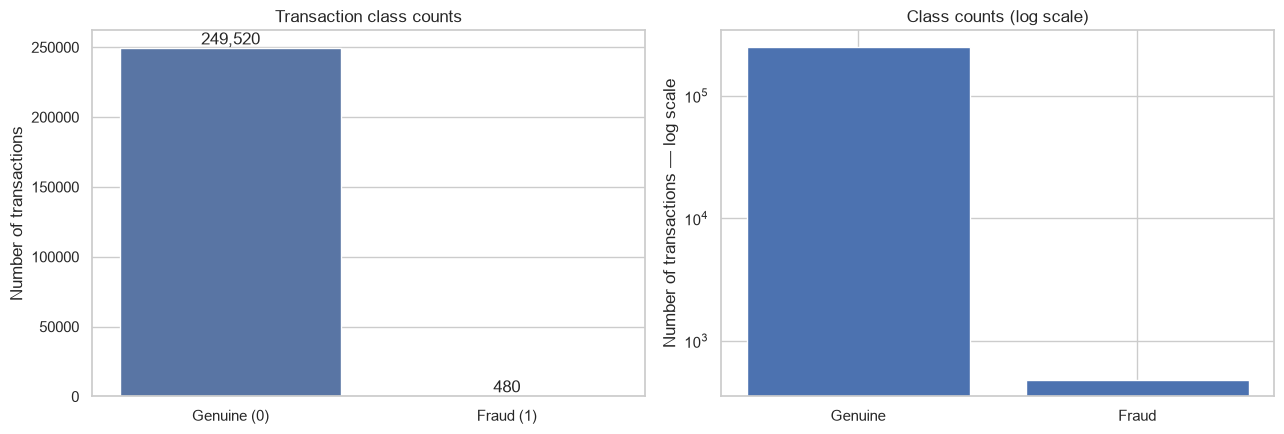

In [8]:
class_counts = df["fraud_flag"].value_counts().reindex([0, 1], fill_value=0)
fraud_rate = df["fraud_flag"].mean() * 100
majority_accuracy = (df["fraud_flag"] == 0).mean() * 100

print(f"Total transactions: {len(df):,}")
print(f"Genuine transactions: {class_counts.loc[0]:,}")
print(f"Fraud transactions: {class_counts.loc[1]:,}")
print(f"Fraud rate: {fraud_rate:.4f}%")
print(f"All-genuine baseline accuracy: {majority_accuracy:.4f}%")
print("All-genuine baseline fraud recall: 0.00%")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=["Genuine (0)", "Fraud (1)"], y=class_counts.values, ax=axes[0])
axes[0].set_title("Transaction class counts")
axes[0].set_ylabel("Number of transactions")
for i, value in enumerate(class_counts.values):
    axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")

axes[1].bar(["Genuine", "Fraud"], class_counts.values)
axes[1].set_yscale("log")
axes[1].set_title("Class counts (log scale)")
axes[1].set_ylabel("Number of transactions — log scale")
plt.tight_layout()
plt.show()


## 8. Transaction amount analysis

Compare amount distributions for genuine and fraudulent transactions. Use a log scale where helpful because transaction amounts are often right-skewed. The IQR rule is used to flag potential outliers, not automatically delete them.


,count,mean,median,min,max,std
fraud_flag,,,,,,
Genuine,249520,"1,311.395",629.000,10,42099,"1,847.211"
Fraud,480,"1,499.231",618.500,28,17718,"2,240.708"


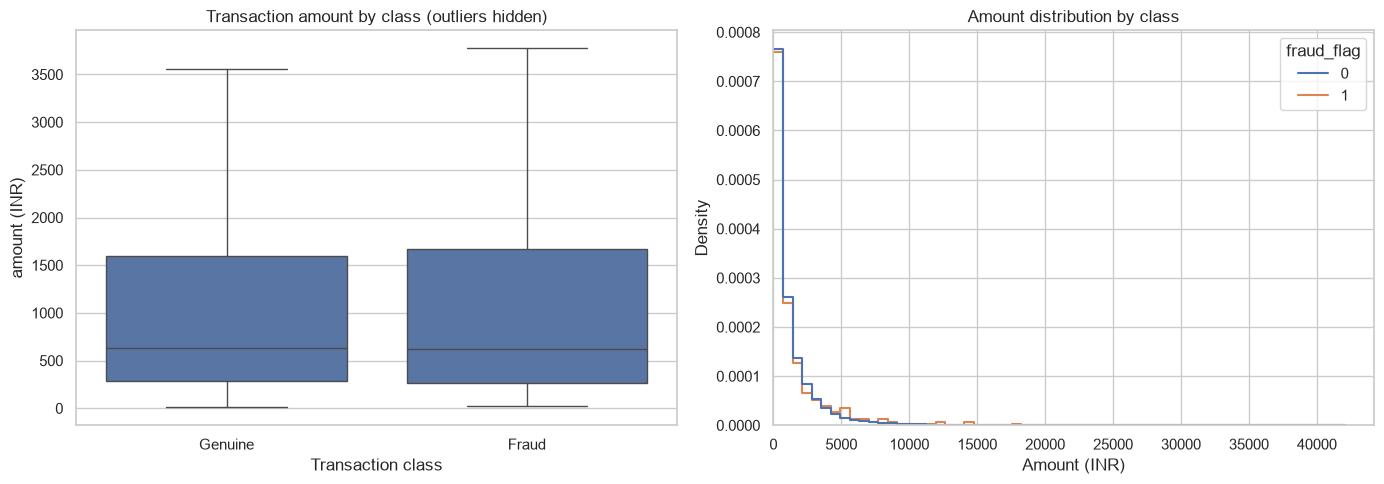

IQR lower bound: ₹-1,674.00
IQR upper bound: ₹3,558.00
Potential amount outliers: 21,171 (8.47%)
Decision: retain valid high-value transactions; investigate them rather than deleting automatically.


In [9]:
display(
    df.groupby("fraud_flag")["amount (INR)"]
      .agg(["count", "mean", "median", "min", "max", "std"])
      .rename(index={0: "Genuine", 1: "Fraud"})
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="fraud_flag", y="amount (INR)", showfliers=False, ax=axes[0])
axes[0].set_xticklabels(["Genuine", "Fraud"])
axes[0].set_title("Transaction amount by class (outliers hidden)")
axes[0].set_xlabel("Transaction class")

sns.histplot(
    data=df, x="amount (INR)", hue="fraud_flag",
    bins=60, stat="density", common_norm=False,
    element="step", fill=False, ax=axes[1]
)
axes[1].set_title("Amount distribution by class")
axes[1].set_xlabel("Amount (INR)")
axes[1].set_xlim(left=0)
plt.tight_layout()
plt.show()

q1 = df["amount (INR)"].quantile(0.25)
q3 = df["amount (INR)"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_count = int(((df["amount (INR)"] < lower_bound) | (df["amount (INR)"] > upper_bound)).sum())

print(f"IQR lower bound: ₹{lower_bound:,.2f}")
print(f"IQR upper bound: ₹{upper_bound:,.2f}")
print(f"Potential amount outliers: {outlier_count:,} ({outlier_count / len(df):.2%})")
print("Decision: retain valid high-value transactions; investigate them rather than deleting automatically.")


## 9. Fraud rate by transaction type and merchant category

Fraud rate is more informative than raw fraud count when groups have different transaction volumes. Always show the group size alongside the rate to avoid over-interpreting tiny groups.


Fraud rate by transaction type:


,transactions,frauds,fraud_rate_pct
transaction type,,,
Recharge,12527,30,0.239
Bill Payment,37368,77,0.206
P2M,87660,167,0.191
P2P,112445,206,0.183


Fraud rate by merchant category:


,transactions,frauds,fraud_rate_pct
merchant_category,,,
Education,7598,16,0.008
Healthcare,12663,21,0.004
Shopping,29872,62,0.002
Utilities,22338,33,-0.001
Grocery,49966,94,-0.001
Fuel,25063,48,-0.003
Transport,20105,43,-0.003
Food,37464,73,-0.003
Entertainment,20103,40,-0.005


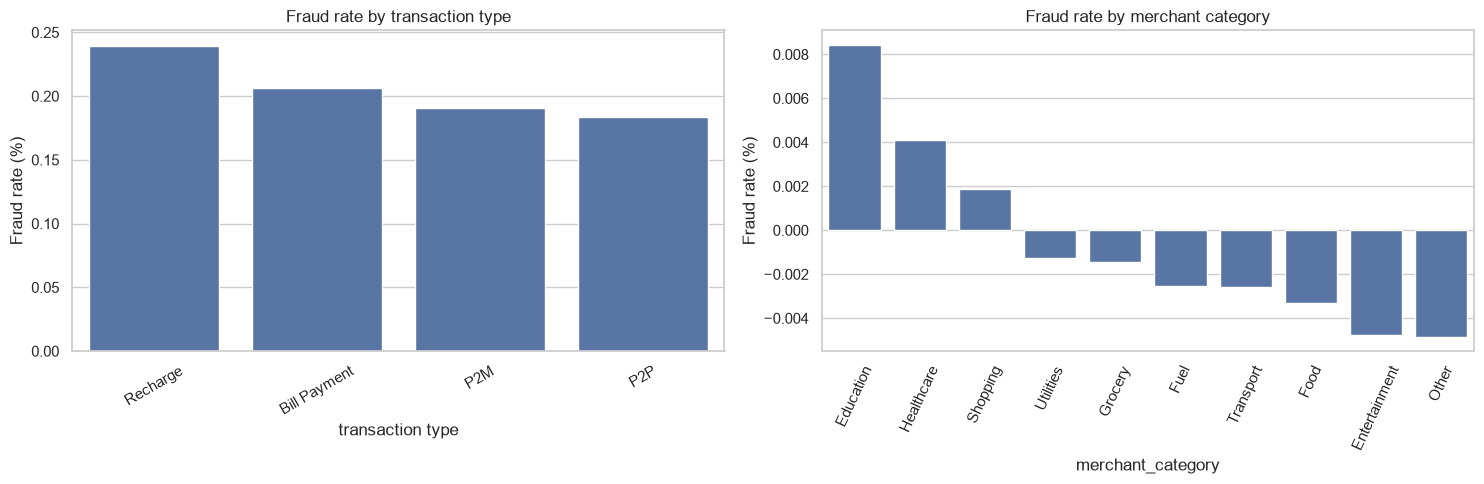

In [10]:
def fraud_rate_table(data, group_col, min_count=1):
    result = (
        data.groupby(group_col, dropna=False)
            .agg(transactions=("fraud_flag", "size"), frauds=("fraud_flag", "sum"))
            .assign(fraud_rate_pct=lambda x: 100 * x["frauds"] / x["transactions"])
            .query("transactions >= @min_count")
            .sort_values("fraud_rate_pct", ascending=False)
    )
    return result

type_stats = fraud_rate_table(df, "transaction type")
category_stats = fraud_rate_table(df, "merchant_category")

print("Fraud rate by transaction type:")
display(type_stats)

print("Fraud rate by merchant category:")
display(category_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=type_stats.reset_index(), x="transaction type", y="fraud_rate_pct", ax=axes[0])
axes[0].set_title("Fraud rate by transaction type")
axes[0].set_ylabel("Fraud rate (%)")
axes[0].tick_params(axis="x", rotation=30)

category_plot = category_stats.reset_index().sort_values("fraud_rate_pct", ascending=False)
sns.barplot(data=category_plot, x="merchant_category", y="fraud_rate_pct", ax=axes[1])
axes[1].set_title("Fraud rate by merchant category")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()


## 10. Fraud patterns over time

Examine fraud rates by hour and day of week. These are descriptive associations, not proof that a particular hour or day causes fraud.


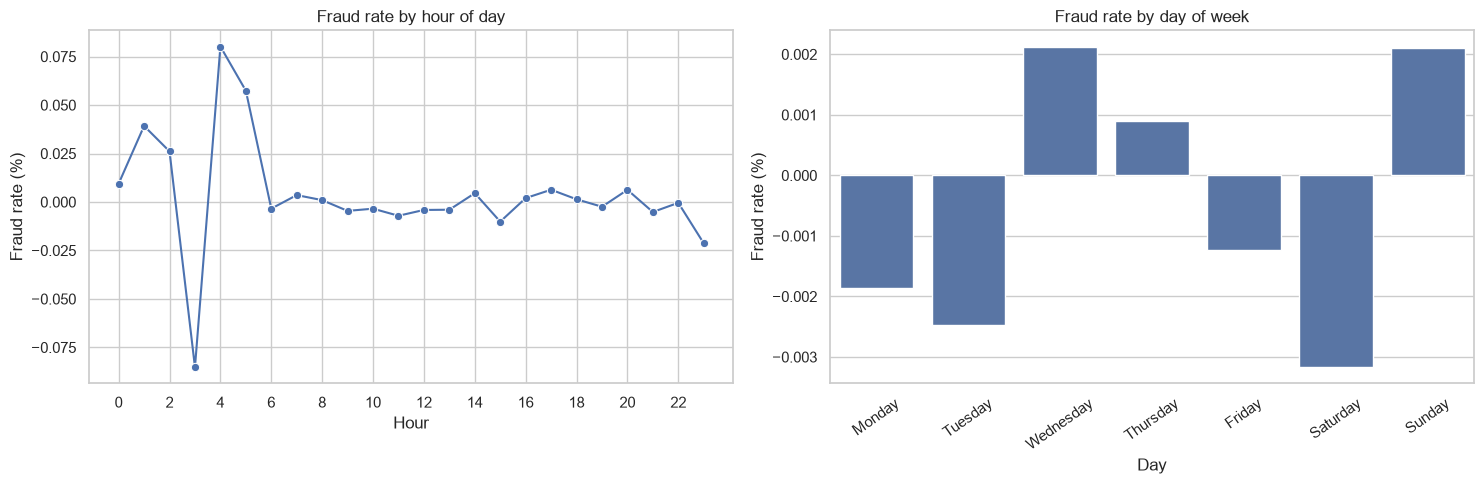

,transactions,frauds,fraud_rate_pct
hour_from_timestamp,,,
0,3388,8,0.009
1,2244,6,0.039
2,1685,3,0.026
3,1314,4,-0.085
4,1247,1,0.080
5,1742,1,0.057
6,3501,5,-0.003
7,5630,13,0.004
8,8349,18,0.001


,transactions,frauds,fraud_rate_pct
day_name_from_timestamp,,,
Monday,36495,71,-0.002
Tuesday,35540,58,-0.002
Wednesday,35700,75,0.002
Thursday,35432,72,0.001
Friday,35496,61,-0.001
Saturday,35334,68,-0.003
Sunday,36003,75,0.002


In [11]:
hour_stats = fraud_rate_table(df, "hour_from_timestamp").sort_index()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_stats = fraud_rate_table(df, "day_name_from_timestamp").reindex(day_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(x=hour_stats.index, y=hour_stats["fraud_rate_pct"], marker="o", ax=axes[0])
axes[0].set_title("Fraud rate by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Fraud rate (%)")
axes[0].set_xticks(range(0, 24, 2))

sns.barplot(x=day_stats.index, y=day_stats["fraud_rate_pct"], ax=axes[1])
axes[1].set_title("Fraud rate by day of week")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

display(hour_stats)
display(day_stats)


## 11. Fraud by state, device and network

These comparisons can reveal where fraud is concentrated in this dataset. Interpret cautiously: differences may reflect transaction volume or how the simulated data was generated.


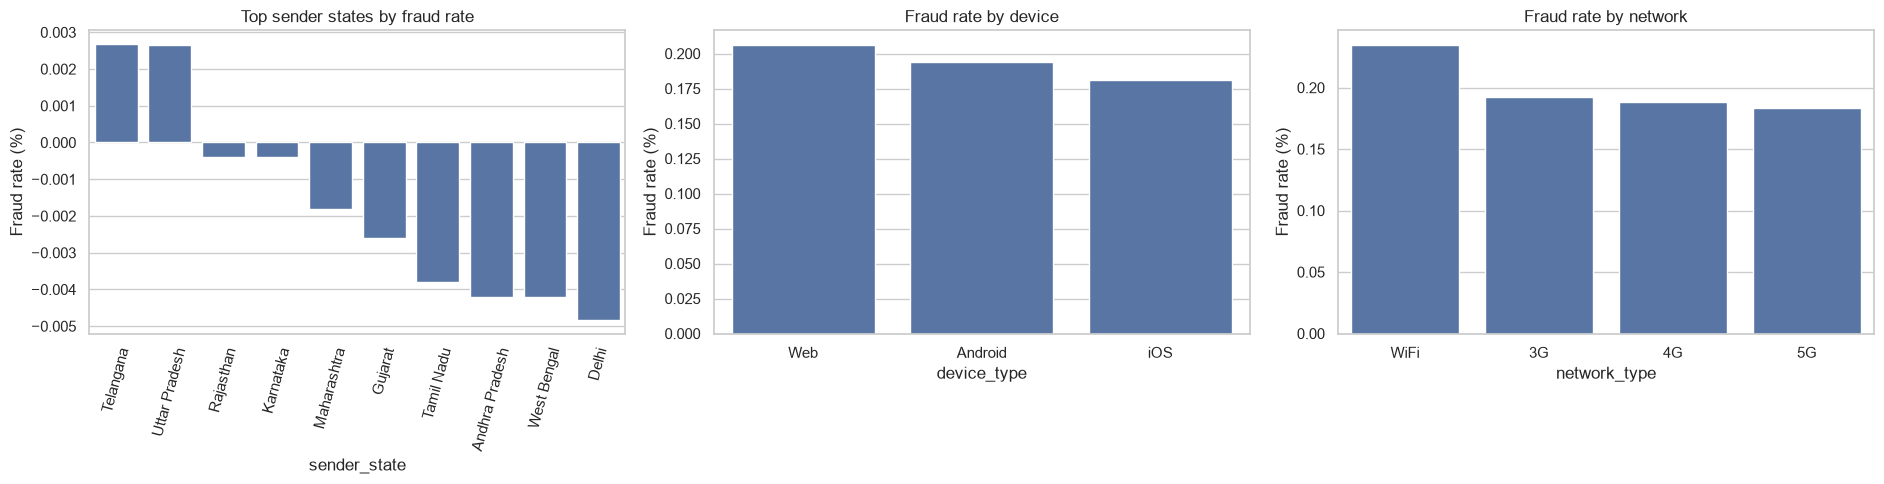

,transactions,frauds,fraud_rate_pct
sender_state,,,
Telangana,22435,39,0.003
Uttar Pradesh,30125,52,0.003
Rajasthan,19981,46,-0.000
Karnataka,29756,69,-0.000
Maharashtra,37427,71,-0.002
Gujarat,20061,43,-0.003
Tamil Nadu,25367,40,-0.004
Andhra Pradesh,20006,35,-0.004
West Bengal,19972,35,-0.004


,transactions,frauds,fraud_rate_pct
device_type,,,
Web,12610,26,0.206
Android,187777,364,0.194
iOS,49613,90,0.181


,transactions,frauds,fraud_rate_pct
network_type,,,
WiFi,25134,59,0.235
3G,12471,24,0.192
4G,149813,282,0.188
5G,62582,115,0.184


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

state_stats = fraud_rate_table(df, "sender_state").sort_values("fraud_rate_pct", ascending=False).head(12)
sns.barplot(data=state_stats.reset_index(), x="sender_state", y="fraud_rate_pct", ax=axes[0])
axes[0].set_title("Top sender states by fraud rate")
axes[0].tick_params(axis="x", rotation=75)
axes[0].set_ylabel("Fraud rate (%)")

device_stats = fraud_rate_table(df, "device_type").sort_values("fraud_rate_pct", ascending=False)
sns.barplot(data=device_stats.reset_index(), x="device_type", y="fraud_rate_pct", ax=axes[1])
axes[1].set_title("Fraud rate by device")
axes[1].set_ylabel("Fraud rate (%)")

network_stats = fraud_rate_table(df, "network_type").sort_values("fraud_rate_pct", ascending=False)
sns.barplot(data=network_stats.reset_index(), x="network_type", y="fraud_rate_pct", ax=axes[2])
axes[2].set_title("Fraud rate by network")
axes[2].set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.show()

display(state_stats)
display(device_stats)
display(network_stats)


## 12. Investigate `transaction_status` for potential target leakage

The status field may be highly associated with the fraud label. That association alone does not prove leakage, but if status is assigned after fraud screening or transaction completion, it must not be used to predict whether to approve the transaction in real time.

Check its distribution by target and make the modelling decision based on the business definition and when the field becomes available.


,transactions,frauds,fraud_rate_pct
transaction_status,,,
SUCCESS,237624,459,0.193
FAILED,12376,21,0.170


fraud_flag,genuine_share,fraud_share
transaction_status,,
FAILED,0.998,0.002
SUCCESS,0.998,0.002


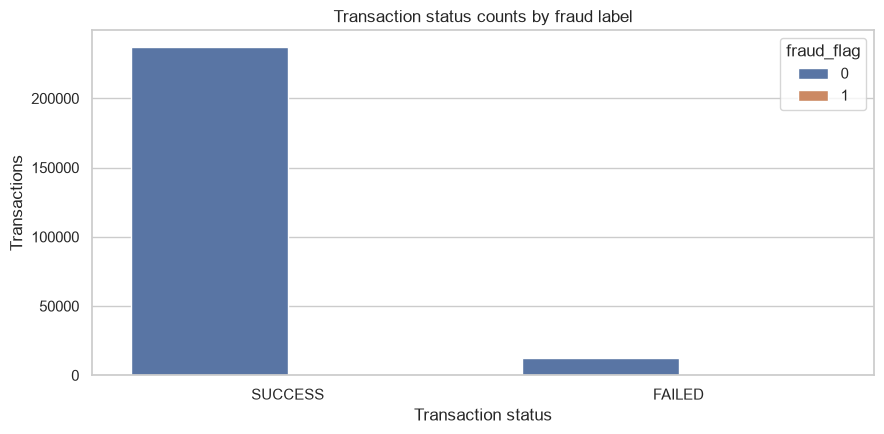

Modelling recommendation: exclude transaction_status from the initial real-time model unless the organiser confirms it is available before the approve/OTP/block decision.


In [13]:
status_stats = fraud_rate_table(df, "transaction_status").sort_values("fraud_rate_pct", ascending=False)
display(status_stats)

status_target = pd.crosstab(
    df["transaction_status"], df["fraud_flag"],
    normalize="index"
).rename(columns={0: "genuine_share", 1: "fraud_share"})
display(status_target)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(data=df, x="transaction_status", hue="fraud_flag", ax=ax)
ax.set_title("Transaction status counts by fraud label")
ax.set_xlabel("Transaction status")
ax.set_ylabel("Transactions")
plt.tight_layout()
plt.show()

print(
    "Modelling recommendation: exclude transaction_status from the initial real-time model "
    "unless the organiser confirms it is available before the approve/OTP/block decision."
)


## 13. Correlation view for numeric fields

Correlation is a quick diagnostic, not a complete feature-selection method. The target is included only for exploratory inspection; it must not be included among model inputs.


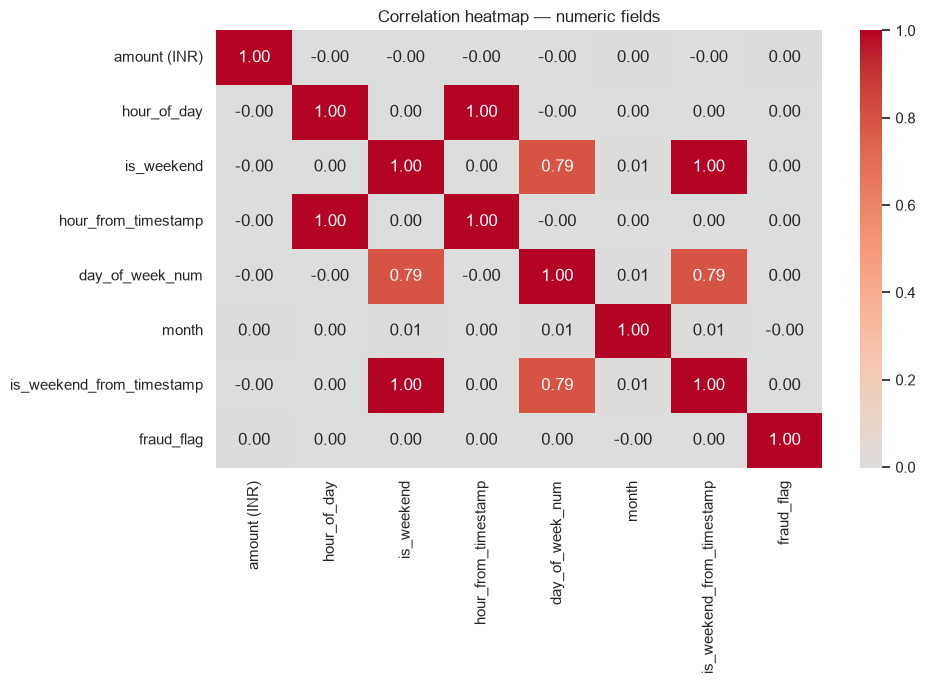

In [14]:
numeric_cols = [
    "amount (INR)", "hour_of_day", "is_weekend",
    "hour_from_timestamp", "day_of_week_num", "month",
    "is_weekend_from_timestamp", "fraud_flag"
]
corr = df[numeric_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap — numeric fields")
plt.tight_layout()
plt.show()


## 14. Prepare a cleaned analysis dataset

This output retains the original useful fields and adds timestamp-derived features. It does not perform one-hot encoding, scaling or SMOTE; those operations belong in the modelling pipeline after the train/test split.

The transaction ID is retained for traceability but must be excluded from model features. `fraud_flag` is the target. `transaction_status` is marked as a potential leakage column.


In [15]:
# Final sanity checks.
assert df["fraud_flag"].isin([0, 1]).all()
assert df["amount (INR)"].gt(0).all()
assert df["timestamp"].notna().all()

cleaned_path = Path("upi_transactions_cleaned.csv")
df.to_csv(cleaned_path, index=False)

# Save a compact data-quality report as well.
quality_report = pd.DataFrame({
    "metric": [
        "rows_in_original_file",
        "rows_after_cleaning",
        "columns",
        "exact_duplicate_rows_removed",
        "invalid_rows_removed",
        "missing_cells_after_cleaning",
        "duplicate_transaction_ids_after_cleaning",
        "fraud_transactions",
        "genuine_transactions",
        "fraud_rate_percent"
    ],
    "value": [
        len(df_raw),
        len(df),
        df.shape[1],
        removed_exact_duplicates,
        removed_invalid_rows,
        int(df.isna().sum().sum()),
        int(df["transaction id"].duplicated().sum()),
        int((df["fraud_flag"] == 1).sum()),
        int((df["fraud_flag"] == 0).sum()),
        round(df["fraud_flag"].mean() * 100, 6)
    ]
})
quality_report.to_csv("upi_data_quality_report.csv", index=False)

print(f"Cleaned dataset saved to: {cleaned_path.resolve()}")
print("Quality report saved to: upi_data_quality_report.csv")
display(quality_report)


Cleaned dataset saved to: C:\Users\thula\Desktop\Hackathon_FraudDetection\upi_transactions_cleaned.csv
Quality report saved to: upi_data_quality_report.csv


,metric,value
0,rows_in_original_file,"250,000.000"
1,rows_after_cleaning,"250,000.000"
2,columns,23.000
3,exact_duplicate_rows_removed,0.000
4,invalid_rows_removed,0.000
5,missing_cells_after_cleaning,0.000
6,duplicate_transaction_ids_after_cleaning,0.000
7,fraud_transactions,480.000
8,genuine_transactions,"249,520.000"
9,fraud_rate_percent,0.192


## 15. Final findings and handoff to modelling

Before proceeding, record the evidence-based findings from the notebook.

### Checklist
- [ ] Confirm the fraud count and fraud percentage.
- [ ] Record the data-quality issues found and how they were treated.
- [ ] Identify the transaction types, merchant categories and time periods with elevated fraud rates.
- [ ] Check whether group sizes are large enough to support comparisons.
- [ ] Confirm the timing/availability of `transaction_status`; exclude it from initial model inputs if it is post-outcome.
- [ ] Keep `transaction id` out of model inputs.
- [ ] Do not use `fraud_flag` as a feature.
- [ ] Split data before applying SMOTE or any resampling.
- [ ] Fit encoders, imputers and scalers on training data only.

### Recommended next notebook
Build the supervised classification notebook using a stratified or time-aware split, a rule baseline, Logistic Regression, Random Forest and Gradient Boosting/XGBoost, with class weights and SMOTE applied only inside the training pipeline.
